MD# SpaceX Falcon 9 – EDA with Data Visualization

In [1]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
%matplotlib inline

In [2]:
import os
# Loads the local copy (data/) if present, otherwise the IBM Skills Network URL
df = pd.read_csv('data/dataset_part_2.csv') if os.path.exists('data/dataset_part_2.csv') else pd.read_csv('https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBM-DS0321EN-SkillsNetwork/datasets/dataset_part_2.csv')
df.head()

,FlightNumber,Date,BoosterVersion,PayloadMass,Orbit,LaunchSite,Outcome,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial,Longitude,Latitude,Class
0,1,2010-06-04,Falcon 9,6104.959412,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0003,-80.577366,28.561857,0
1,2,2012-05-22,Falcon 9,525.000000,LEO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0005,-80.577366,28.561857,0
2,3,2013-03-01,Falcon 9,677.000000,ISS,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B0007,-80.577366,28.561857,0
3,4,2013-09-29,Falcon 9,500.000000,PO,VAFB SLC 4E,False Ocean,1,False,False,False,NaN,1.0,0,B1003,-120.610829,34.632093,0
4,5,2013-12-03,Falcon 9,3170.000000,GTO,CCAFS SLC 40,None None,1,False,False,False,NaN,1.0,0,B1004,-80.577366,28.561857,0


MD### Flight number vs payload mass

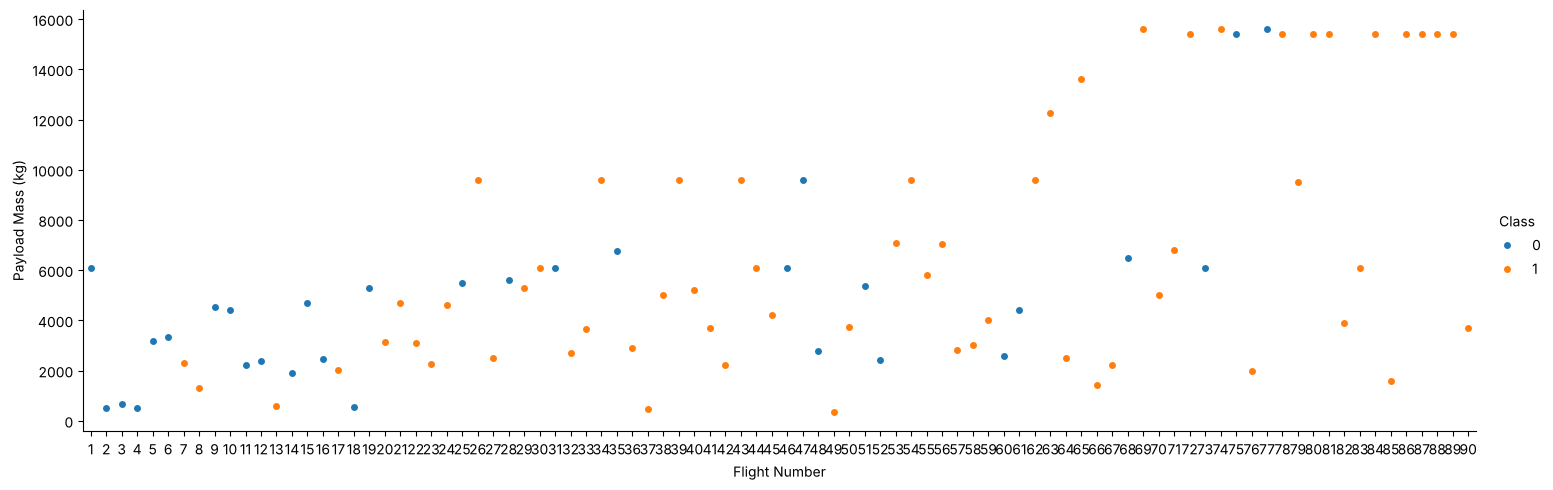

In [3]:
sns.catplot(y='PayloadMass', x='FlightNumber', hue='Class', data=df, aspect=3)
plt.xlabel('Flight Number'); plt.ylabel('Payload Mass (kg)'); plt.show()

MD### Task 1 – Flight number vs launch site

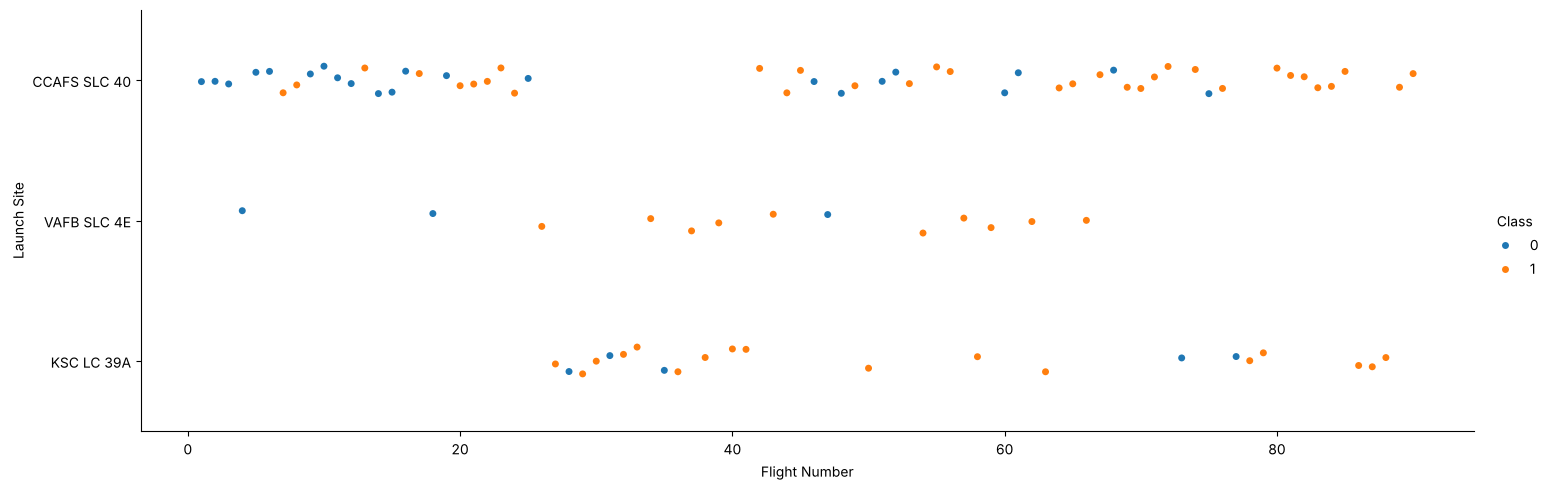

In [4]:
sns.catplot(y='LaunchSite', x='FlightNumber', hue='Class', data=df, aspect=3)
plt.xlabel('Flight Number'); plt.ylabel('Launch Site'); plt.show()

MD### Task 2 – Payload mass vs launch site

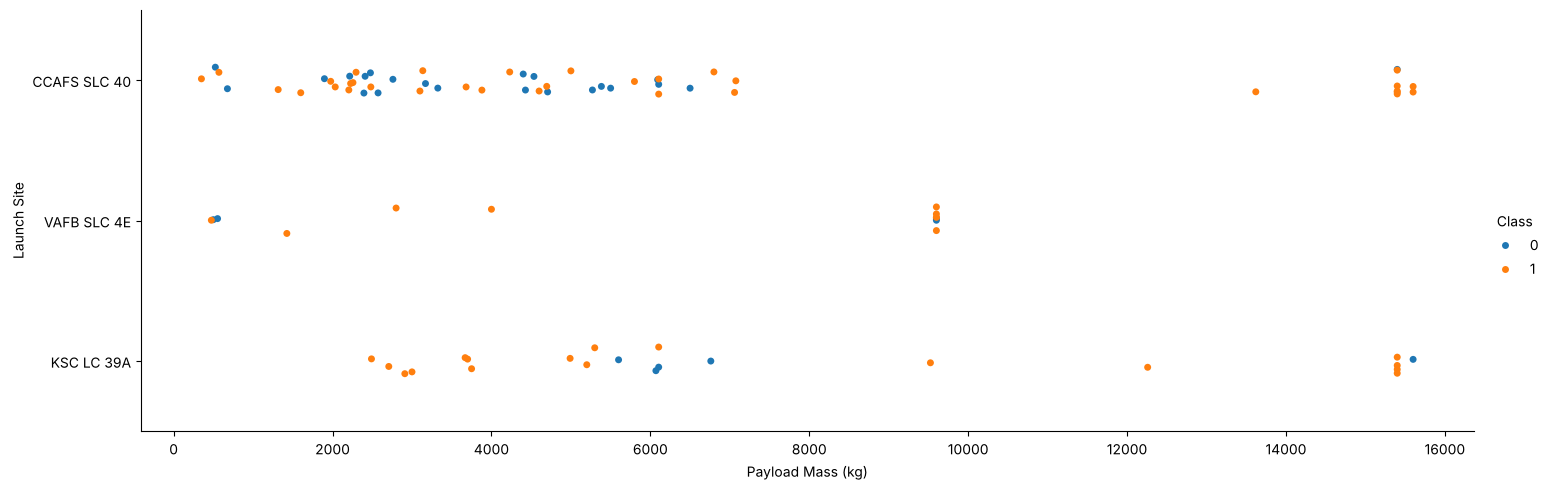

In [5]:
sns.catplot(y='LaunchSite', x='PayloadMass', hue='Class', data=df, aspect=3)
plt.xlabel('Payload Mass (kg)'); plt.ylabel('Launch Site'); plt.show()

MD### Task 3 – Success rate of each orbit type

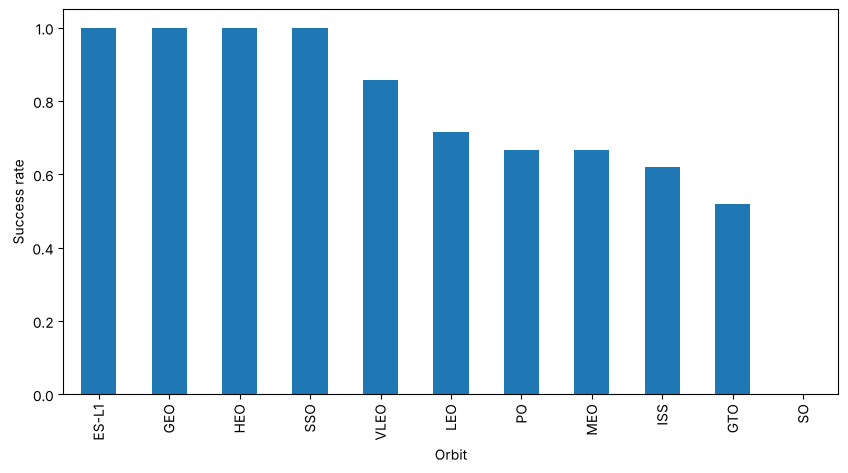

Orbit
ES-L1    1.000000
GEO      1.000000
HEO      1.000000
SSO      1.000000
VLEO     0.857143
LEO      0.714286
PO       0.666667
MEO      0.666667
ISS      0.619048
GTO      0.518519
SO       0.000000
Name: Class, dtype: float64

In [6]:
orbit_rate = df.groupby('Orbit')['Class'].mean().sort_values(ascending=False)
orbit_rate.plot(kind='bar', figsize=(10,5)); plt.ylabel('Success rate'); plt.show()
orbit_rate

MD### Task 4 – Flight number vs orbit type

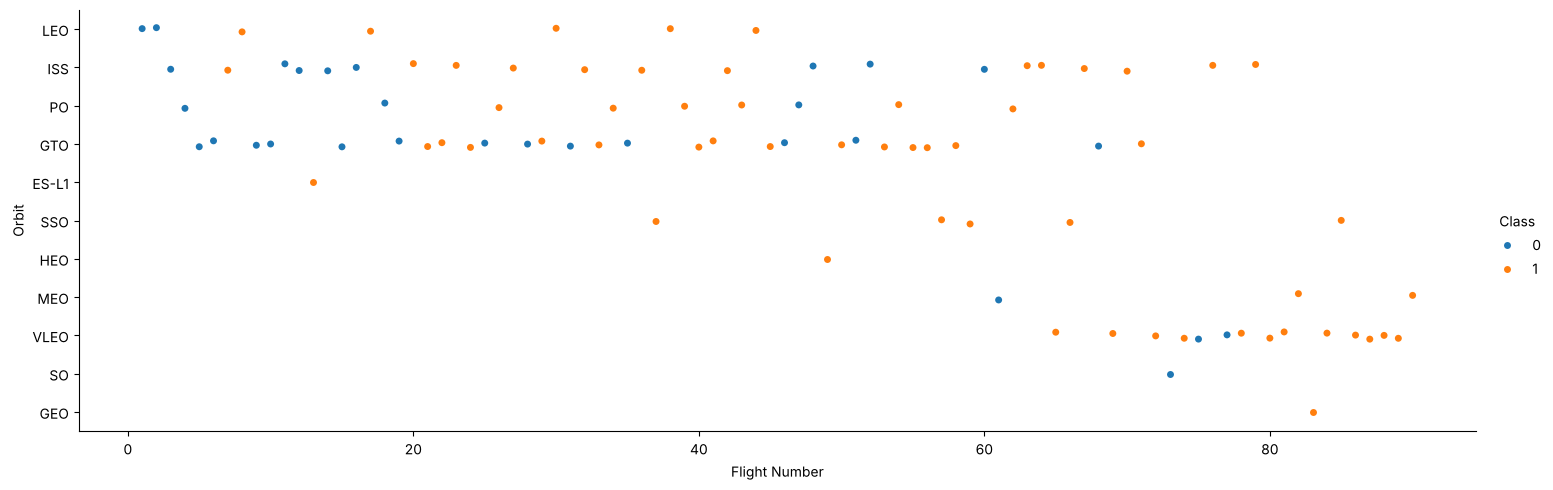

In [7]:
sns.catplot(y='Orbit', x='FlightNumber', hue='Class', data=df, aspect=3)
plt.xlabel('Flight Number'); plt.ylabel('Orbit'); plt.show()

MD### Task 5 – Payload mass vs orbit type

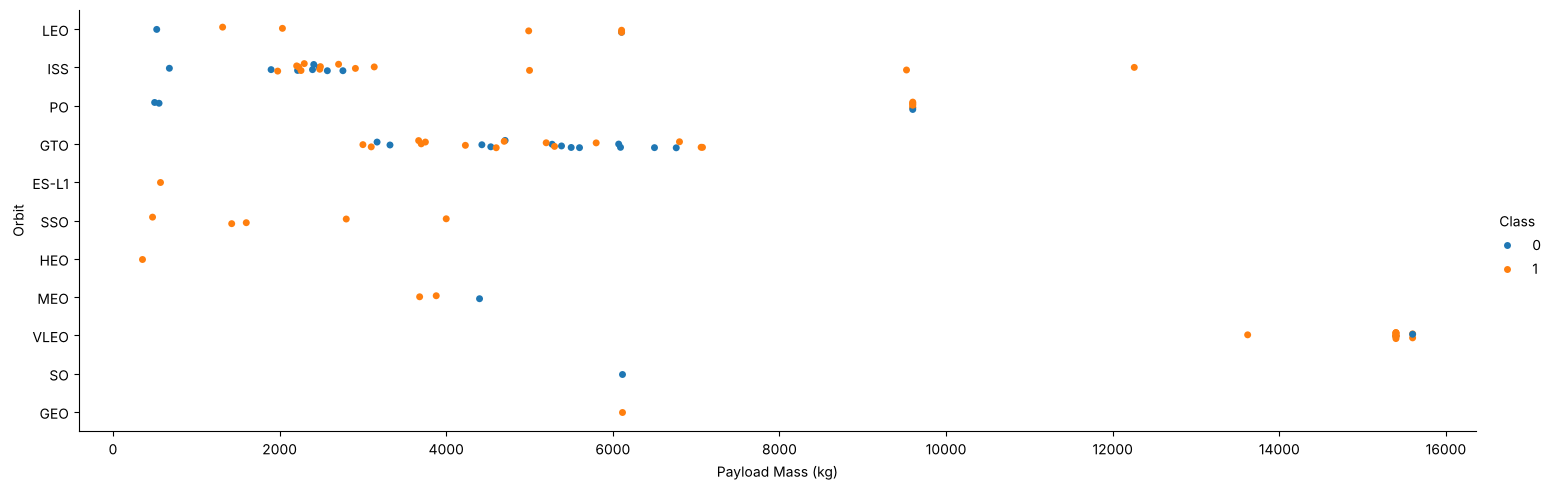

In [8]:
sns.catplot(y='Orbit', x='PayloadMass', hue='Class', data=df, aspect=3)
plt.xlabel('Payload Mass (kg)'); plt.ylabel('Orbit'); plt.show()

MD### Task 6 – Yearly launch success trend

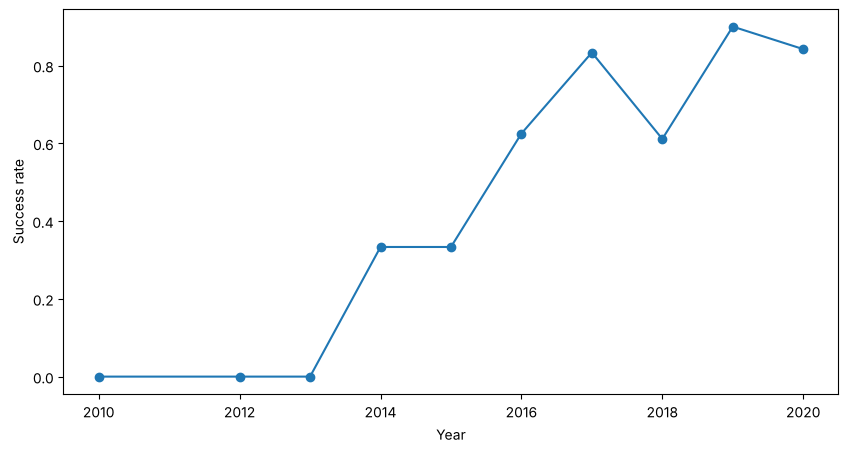

Year
2010    0.000000
2012    0.000000
2013    0.000000
2014    0.333333
2015    0.333333
2016    0.625000
2017    0.833333
2018    0.611111
2019    0.900000
2020    0.842105
Name: Class, dtype: float64

In [9]:
df['Year'] = pd.to_datetime(df['Date']).dt.year
yearly = df.groupby('Year')['Class'].mean()
yearly.plot(kind='line', marker='o', figsize=(10,5)); plt.ylabel('Success rate'); plt.show()
yearly

MD## Feature engineering

In [10]:
features = df[['FlightNumber','PayloadMass','Orbit','LaunchSite','Flights','GridFins','Reused','Legs','LandingPad','Block','ReusedCount','Serial']]
features.head()

,FlightNumber,PayloadMass,Orbit,LaunchSite,Flights,GridFins,Reused,Legs,LandingPad,Block,ReusedCount,Serial
0,1,6104.959412,LEO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0003
1,2,525.000000,LEO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0005
2,3,677.000000,ISS,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B0007
3,4,500.000000,PO,VAFB SLC 4E,1,False,False,False,NaN,1.0,0,B1003
4,5,3170.000000,GTO,CCAFS SLC 40,1,False,False,False,NaN,1.0,0,B1004


MD### Task 7 – One-hot encoding of categorical columns

In [11]:
features_one_hot = pd.get_dummies(features, columns=['Orbit','LaunchSite','LandingPad','Serial'])
features_one_hot.shape

(90, 80)

MD### Task 8 – Cast all numeric columns to float64

In [12]:
features_one_hot = features_one_hot.astype('float64')
features_one_hot.to_csv('dataset_part_3.csv', index=False)
features_one_hot.dtypes.value_counts()

float64    80
Name: count, dtype: int64